In [1]:
"""
PLAN (one notebook, run top to bottom)
Part 1 (Tasks 1-48): variation, related features, and prediction of the county share rated 70%+ with state-grouped vs random cross-validation.
Part 2: robustness checks (weighting, leave-one-state-out, Census regions, tests, fixed effects).
Part 3: tuned models with nested state-grouped CV; improvement rule fixed before the run (bootstrap CI lower bound > 0).
Part 4: comparison with the verified literature (validation gap, method map). No published benchmark exists for this outcome.
Data: data/raw/Disability.csv, seed 42, 5-fold x 10 repeats. Associations only, no causal claims.
"""

'\nPLAN (one notebook, run top to bottom)\nPart 1 (Tasks 1-48): variation, related features, and prediction of the county share rated 70%+ with state-grouped vs random cross-validation.\nPart 2: robustness checks (weighting, leave-one-state-out, Census regions, tests, fixed effects).\nPart 3: tuned models with nested state-grouped CV; improvement rule fixed before the run (bootstrap CI lower bound > 0).\nPart 4: comparison with the verified literature (validation gap, method map). No published benchmark exists for this outcome.\nData: data/raw/Disability.csv, seed 42, 5-fold x 10 repeats. Associations only, no causal claims.\n'

In [2]:
# Task 1: Import the libraries
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

In [3]:
# Task 2: Settings
DATA_FILE = Path("../data/raw/Disability.csv")
RESULTS = Path("../results")
RESULTS.mkdir(exist_ok=True)

SEED = 42
N_REPEATS = 10      # cross-validation repeats
N_FOLDS = 5         # folds per repeat
N_BOOT = 2000       # bootstrap resamples

In [4]:
# Task 3: Plot style used by every figure
BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": MUTED, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.8, "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "font.size": 10, "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
})

In [5]:
# Task 4: Load the dataset as text (the raw file is never changed)
raw = pd.read_csv(DATA_FILE, dtype=str)
print("Rows and columns:", raw.shape)
raw.head()

Rows and columns: (3148, 14)


,FIPS code,State,County Name,Total: Disability Compensation Recipients,SCD rating: 0% to 20%,SCD rating: 30% to 40%,SCD rating: 50% to 60%,SCD rating: 70% to 90%,SCD rating: 100%,Age: 17-44,Age: 45-64,Age: 65 or older,Male,Female
0,01001,Alabama,Autauga,"2,949",420,250,346,924,"1,009",763,"1,278",908,"2,382",567
1,01003,Alabama,Baldwin,"7,650","1,590",780,909,"2,249","2,122","1,698","2,591","3,360","6,905",745
2,01005,Alabama,Barbour,646,102,48,75,207,214,108,240,298,564,82
3,01007,Alabama,Bibb,324,52,37,37,115,83,70,118,136,298,26
4,01009,Alabama,Blount,"1,088",182,132,146,342,286,288,326,474,"1,011",77


In [6]:
# Task 5: Give the columns short names
raw.columns = ["fips", "state", "county", "total", "r0_20", "r30_40", "r50_60", "r70_90", "r100",
               "age_17_44", "age_45_64", "age_65_plus", "male", "female"]
COUNTS = list(raw.columns[3:])
print(COUNTS)

['total', 'r0_20', 'r30_40', 'r50_60', 'r70_90', 'r100', 'age_17_44', 'age_45_64', 'age_65_plus', 'male', 'female']


In [7]:
# Task 6: Turn the count columns into numbers ("2,949" -> 2949, blank -> missing)
for c in COUNTS:
    raw[c] = pd.to_numeric(raw[c].str.replace(",", ""), errors="coerce")
raw[COUNTS].describe().loc[["count", "min", "50%", "max"]].T

,count,min,50%,max
total,3135.0,10.0,542.0,98159.0
r0_20,2984.0,10.0,130.0,15874.0
r30_40,2820.0,10.0,73.0,9364.0
r50_60,2833.0,10.0,80.0,10303.0
r70_90,3027.0,10.0,167.0,28075.0
r100,2987.0,10.0,144.0,38153.0
age_17_44,2966.0,10.0,130.0,37669.0
age_45_64,2969.0,10.0,183.0,37519.0
age_65_plus,3075.0,10.0,265.0,27556.0
male,2684.0,48.0,646.0,84275.0


In [8]:
# Task 7: Show the rows that are not counties
NOT_COUNTY = ["72000", "88888", "00000", "Unknown"]
raw[raw.fips.isin(NOT_COUNTY)][["fips", "state", "total"]]

,fips,state,total
3144,72000,Puerto Rico,36399.0
3145,88888,US Territories (excluding Puerto Rico),7699.0
3146,00000,Other Foreign Countries,38497.0
3147,Unknown,Unknown,229.0


In [9]:
# Task 8: Keep only the county rows
df = raw[~raw.fips.isin(NOT_COUNTY)].copy()
print(f"{len(df):,} counties in {df.state.nunique()} states (50 states + DC)")

3,144 counties in 51 states (50 states + DC)


In [10]:
# Task 9: Check for duplicate counties
print("Duplicate FIPS codes:", df.fips.duplicated().sum())
print("Duplicate rows      :", df.duplicated().sum())

Duplicate FIPS codes: 0
Duplicate rows      : 0


In [11]:
# Task 10: Count the blank cells in each column
audit = pd.DataFrame({
    "blank_counties": df[COUNTS].isna().sum(),
    "blank_pct": (df[COUNTS].isna().mean() * 100).round(1),
    "smallest_value": df[COUNTS].min().astype(int),
})
audit.to_csv(RESULTS / "table_01_blank_cells.csv")
audit

,blank_counties,blank_pct,smallest_value
total,13,0.4,10
r0_20,164,5.2,10
r30_40,327,10.4,10
r50_60,314,10.0,10
r70_90,121,3.8,10
r100,161,5.1,10
age_17_44,182,5.8,10
age_45_64,179,5.7,10
age_65_plus,73,2.3,10
male,464,14.8,48


In [12]:
# Task 11: Check that male and female are always blank together
print("Male and female blank together:", (df.male.isna() == df.female.isna()).all())

Male and female blank together: True


In [13]:
# Task 12: Check that the parts add up to the total where nothing is hidden
full = df.dropna(subset=COUNTS)
checks = pd.Series({
    "rating bands sum to total": (full[["r0_20", "r30_40", "r50_60", "r70_90", "r100"]].sum(axis=1) == full.total).mean(),
    "age bands sum to total": (full[["age_17_44", "age_45_64", "age_65_plus"]].sum(axis=1) == full.total).mean(),
    "male + female = total": (full[["male", "female"]].sum(axis=1) == full.total).mean(),
})
print(f"Counties with no blank cell: {len(full):,}")
(checks * 100).round(1).rename("% of those counties")

Counties with no blank cell: 2,649


rating bands sum to total    100.0
age bands sum to total        98.9
male + female = total         81.8
Name: % of those counties, dtype: float64

In [14]:
# Task 13: Create the two outcomes
df["high_share"] = (df.r70_90 + df.r100) / df.total      # main outcome: rated 70% or higher
df["full_share"] = df.r100 / df.total                    # second outcome: rated 100%
df[["high_share", "full_share"]].describe().loc[["count", "mean", "min", "max"]].round(3)

,high_share,full_share
count,2961.000,2983.000
mean,0.545,0.254
min,0.242,0.076
max,0.840,0.571


In [15]:
# Task 14: Create the four features
df["young_share"] = df.age_17_44 / df.total
df["older_share"] = df.age_65_plus / df.total
df["female_share"] = df.female / df.total
df["log_total"] = np.log10(df.total)

FEATURES = ["young_share", "older_share", "female_share", "log_total"]
LABELS = {"young_share": "Share aged 17–44", "older_share": "Share aged 65 or older",
          "female_share": "Share female", "log_total": "County size (log10 recipients)"}
df[FEATURES].describe().loc[["count", "mean", "min", "max"]].round(3)

,young_share,older_share,female_share,log_total
count,2962.000,3071.000,2680.000,3131.000
mean,0.235,0.460,0.099,2.780
min,0.066,0.129,0.027,1.000
max,0.520,0.776,0.266,4.992


In [16]:
# Task 15: Select the main sample (counties with the outcome and all four features)
main = df.dropna(subset=["high_share"] + FEATURES).reset_index(drop=True)
print(f"Main sample: {len(main):,} of {len(df):,} counties "
      f"({main.total.sum() / df.total.sum():.1%} of all county recipients)")

Main sample: 2,674 of 3,144 counties (99.4% of all county recipients)


In [17]:
# Task 16: Compare the counties kept with the counties left out
df["in_main"] = df.fips.isin(main.fips)
selection = df.groupby("in_main").total.describe()[["count", "min", "50%", "max"]]
selection.index = ["left out", "main sample"]
selection.to_csv(RESULTS / "table_02_sample_selection.csv")
selection

,count,min,50%,max
left out,457.0,10.0,67.0,285.0
main sample,2674.0,62.0,710.5,98159.0


In [18]:
# Task 17: Pooled high-rating share of all counties
national = (main.r70_90.sum() + main.r100.sum()) / main.total.sum()
print(f"Pooled share rated 70%+ (main sample): {national:.1%}")

Pooled share rated 70%+ (main sample): 58.6%


In [19]:
# Task 18: Spread of the county shares
q = main.high_share.quantile([0.05, 0.25, 0.5, 0.75, 0.95])
(q * 100).round(1).rename("high-rating share (%)")

0.05    39.5
0.25    50.0
0.50    55.8
0.75    60.5
0.95    66.2
Name: high-rating share (%), dtype: float64

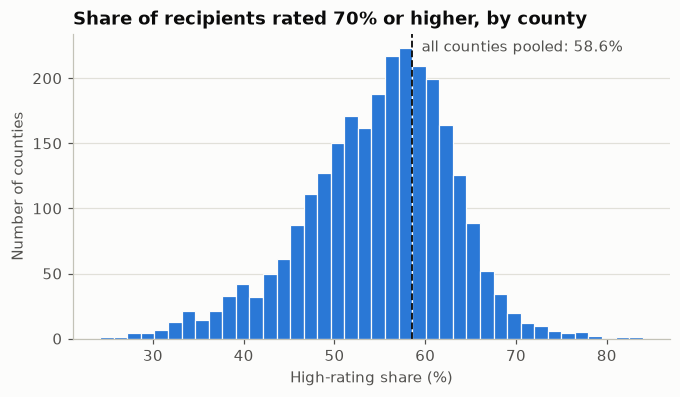

In [20]:
# Task 19: Figure — distribution of the county shares
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.hist(main.high_share * 100, bins=40, color=BLUE, edgecolor=SURFACE, linewidth=0.8)
ax.axvline(national * 100, color=INK, linewidth=1.2, linestyle="--")
ax.annotate(f"all counties pooled: {national:.1%}", (national * 100, ax.get_ylim()[1]),
            xytext=(6, -4), textcoords="offset points", va="top", color=MUTED)
ax.set(title="Share of recipients rated 70% or higher, by county",
       xlabel="High-rating share (%)", ylabel="Number of counties")
ax.grid(axis="x", visible=False)
fig.savefig(RESULTS / "fig_01_county_distribution.png")
plt.show()

In [21]:
# Task 20: Observed spread against the spread expected from chance
observed_var = main.high_share.var()
chance_var = (national * (1 - national) / main.total).mean()
noise_ceiling = 1 - chance_var / observed_var
print(f"Observed SD of county shares     : {np.sqrt(observed_var) * 100:.2f} points")
print(f"SD expected from chance alone    : {np.sqrt(chance_var) * 100:.2f} points")
print(f"Share of variance that is not chance: {noise_ceiling:.1%}  (upper limit for any model's R²)")

Observed SD of county shares     : 8.10 points
SD expected from chance alone    : 2.23 points
Share of variance that is not chance: 92.4%  (upper limit for any model's R²)


In [22]:
# Task 21: Test H1 — chi-square test that all counties have the same share
chi2 = (((main.high_share - national) ** 2) / (national * (1 - national) / main.total)).sum()
p_value = stats.chi2.sf(chi2, len(main) - 1)
print(f"chi-square = {chi2:,.0f} on {len(main) - 1:,} df, p {'< 1e-300' if p_value == 0 else f'= {p_value:.3g}'}")

chi-square = 157,337 on 2,673 df, p < 1e-300


In [23]:
# Task 22: High-rating share of each state
by_state = main.groupby("state").agg(counties=("fips", "size"), recipients=("total", "sum"),
                                     high=("r70_90", "sum"), full=("r100", "sum"))
by_state["high_share"] = (by_state.high + by_state.full) / by_state.recipients
by_state = by_state.sort_values("high_share")
by_state[["counties", "recipients", "high_share"]].round(4).to_csv(RESULTS / "table_03_state_high_share.csv")
pd.concat([by_state.head(5), by_state.tail(5)])[["counties", "recipients", "high_share"]]

,counties,recipients,high_share
state,,,
Minnesota,73,105058.0,0.378534
Nebraska,42,45486.0,0.448731
Indiana,89,115775.0,0.454088
Iowa,88,51181.0,0.468103
South Dakota,30,21776.0,0.477314
Alabama,67,141973.0,0.633360
Georgia,150,273124.0,0.649785
Nevada,12,79982.0,0.650846
Texas,179,678548.0,0.653912


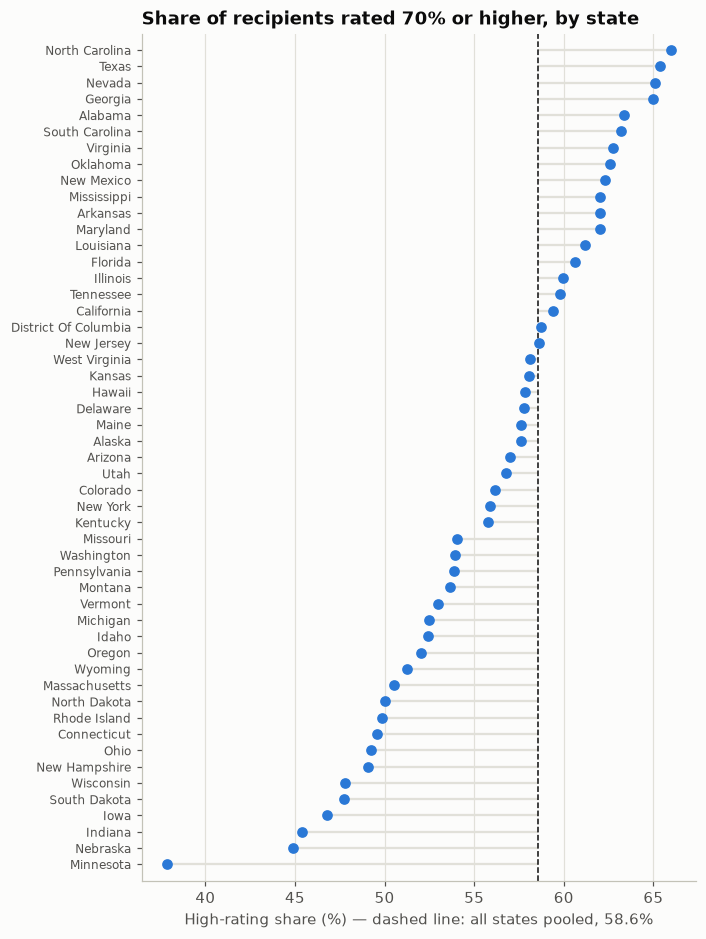

In [24]:
# Task 23: Figure — states ranked by high-rating share
fig, ax = plt.subplots(figsize=(6.5, 10))
y = np.arange(len(by_state))
ax.hlines(y, national * 100, by_state.high_share * 100, color=GRID, linewidth=1.5)
ax.scatter(by_state.high_share * 100, y, s=36, color=BLUE, zorder=3)
ax.axvline(national * 100, color=INK, linewidth=1, linestyle="--")
ax.set_yticks(y, by_state.index, fontsize=8)
ax.set_ylim(-1, len(by_state))
ax.set(title="Share of recipients rated 70% or higher, by state",
       xlabel=f"High-rating share (%) — dashed line: all states pooled, {national:.1%}")
ax.grid(axis="y", visible=False)
fig.savefig(RESULTS / "fig_02_state_ranking.png")
plt.show()

In [25]:
# Task 24: Share of the county variance that lies between states
state_mean = main.groupby("state").high_share.transform("mean")
grand_mean = main.high_share.mean()
between = ((state_mean - grand_mean) ** 2).sum() / ((main.high_share - grand_mean) ** 2).sum()
print(f"Share of county variance that lies between states: {between:.1%}")

Share of county variance that lies between states: 63.3%


In [26]:
# Task 25: Draw the bootstrap resamples of whole states
rng = np.random.default_rng(SEED)
states = main.state.unique()
rows_of = {s: np.flatnonzero(main.state.values == s) for s in states}
boot_rows = [np.concatenate([rows_of[s] for s in rng.choice(states, len(states))]) for _ in range(N_BOOT)]
print(f"{len(boot_rows):,} resamples of {len(states)} states")

2,000 resamples of 51 states


In [27]:
# Task 26: Spearman correlation of each feature with the high-rating share
def spearman(data, feature):
    return stats.spearmanr(data[feature], data["high_share"]).statistic

corr = pd.DataFrame({"spearman": [spearman(main, f) for f in FEATURES]}, index=[LABELS[f] for f in FEATURES])
corr.round(3)

,spearman
Share aged 17–44,0.176
Share aged 65 or older,-0.436
Share female,0.490
County size (log10 recipients),0.165


In [28]:
# Task 27: Test H2 — 95% confidence intervals for the correlations
for f in FEATURES:
    boots = [spearman(main.iloc[r], f) for r in boot_rows]
    corr.loc[LABELS[f], ["ci_low", "ci_high"]] = np.percentile(boots, [2.5, 97.5])
corr = corr.round(3)
corr.index.name = "feature"
corr.to_csv(RESULTS / "table_04_spearman.csv")
corr

,spearman,ci_low,ci_high
feature,,,
Share aged 17–44,0.176,0.038,0.298
Share aged 65 or older,-0.436,-0.538,-0.319
Share female,0.490,0.360,0.585
County size (log10 recipients),0.165,0.060,0.280


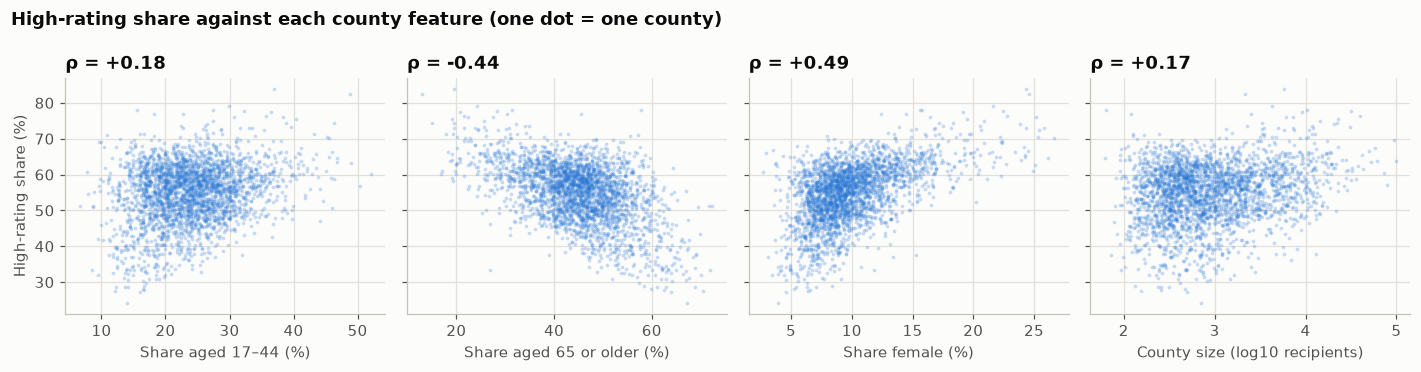

In [29]:
# Task 28: Figure — high-rating share against each feature
fig, axes = plt.subplots(1, 4, figsize=(13, 3.4), sharey=True)
for ax, f in zip(axes, FEATURES):
    x = main[f] if f == "log_total" else main[f] * 100
    ax.scatter(x, main.high_share * 100, s=6, color=BLUE, alpha=0.25, linewidths=0)
    ax.set(xlabel=LABELS[f] + ("" if f == "log_total" else " (%)"),
           title=f"ρ = {corr.loc[LABELS[f], 'spearman']:+.2f}")
axes[0].set_ylabel("High-rating share (%)")
fig.suptitle("High-rating share against each county feature (one dot = one county)",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig(RESULTS / "fig_03_feature_scatter.png")
plt.show()

In [30]:
# Task 29: Linear model with all four features (standardised coefficients)
def std_coefs(data):
    X = (data[FEATURES] - data[FEATURES].mean()) / data[FEATURES].std()
    return LinearRegression().fit(X, data["high_share"] * 100).coef_

coefs = pd.DataFrame({"points_per_sd": std_coefs(main)}, index=[LABELS[f] for f in FEATURES])
coefs.round(2)

,points_per_sd
Share aged 17–44,-3.52
Share aged 65 or older,-5.70
Share female,1.96
County size (log10 recipients),0.03


In [31]:
# Task 30: 95% confidence intervals for the coefficients
boots = np.array([std_coefs(main.iloc[r]) for r in boot_rows])
coefs["ci_low"] = np.percentile(boots, 2.5, axis=0)
coefs["ci_high"] = np.percentile(boots, 97.5, axis=0)
coefs = coefs.round(2)
coefs["one_sd_equals"] = [f"{main[f].std() * 100:.1f} points" if f != "log_total" else f"×{10 ** main[f].std():.1f} recipients"
                          for f in FEATURES]
coefs.to_csv(RESULTS / "table_05_linear_coefficients.csv")
coefs

,points_per_sd,ci_low,ci_high,one_sd_equals
Share aged 17–44,-3.52,-4.85,-2.16,6.4 points
Share aged 65 or older,-5.70,-7.98,-3.30,8.9 points
Share female,1.96,0.98,3.11,3.4 points
County size (log10 recipients),0.03,-0.68,0.89,×3.5 recipients


In [32]:
# Task 31: Prepare the arrays for modelling
X_all = main[FEATURES].values
y_all = main.high_share.values * 100          # in percentage points
state_all = main.state.values
print("X:", X_all.shape, "| y:", y_all.shape, "| states:", len(np.unique(state_all)))

X: (2674, 4) | y: (2674,) | states: 51


In [33]:
# Task 32: Define the random folds
def random_folds(repeat):
    splitter = KFold(N_FOLDS, shuffle=True, random_state=SEED + repeat)
    return [test for _, test in splitter.split(X_all)]

print("Test counties per fold:", [len(t) for t in random_folds(0)])

Test counties per fold: [535, 535, 535, 535, 534]


In [34]:
# Task 33: Define the state-grouped folds
def state_folds(repeat):
    order = np.random.default_rng(SEED + repeat).permutation(np.unique(state_all))
    return [np.flatnonzero(np.isin(state_all, chunk)) for chunk in np.array_split(order, N_FOLDS)]

print("Test counties per fold:", [len(t) for t in state_folds(0)])

Test counties per fold: [554, 429, 595, 552, 544]


In [35]:
# Task 34: Define the 'state average' predictor
def predict_state_average(train, test):
    means = pd.Series(y_all[train]).groupby(state_all[train]).mean()
    return pd.Series(state_all[test]).map(means).fillna(y_all[train].mean()).values

In [36]:
# Task 35: Define the four predictors
def from_sklearn(model):
    return lambda train, test: model.fit(X_all[train], y_all[train]).predict(X_all[test])

MODELS = {
    "Overall average (baseline)": from_sklearn(DummyRegressor()),
    "State average": predict_state_average,
    "Linear regression": from_sklearn(make_pipeline(StandardScaler(), LinearRegression())),
    "Gradient boosting": from_sklearn(HistGradientBoostingRegressor(max_depth=3, learning_rate=0.05,
                                                                    max_iter=200, random_state=SEED)),
}
print(list(MODELS))

['Overall average (baseline)', 'State average', 'Linear regression', 'Gradient boosting']


In [37]:
# Task 36: Define one cross-validation run (out-of-fold predictions for every county)
def out_of_fold(fit_predict, folds):
    everyone = np.arange(len(y_all))
    pred = np.empty(len(y_all))
    for test in folds:
        train = np.setdiff1d(everyone, test)
        pred[test] = fit_predict(train, test)
    return pred

In [38]:
# Task 37: Run every predictor under both fold designs
rows = []
for scheme, make_folds in [("Random folds", random_folds), ("State-grouped folds", state_folds)]:
    for repeat in range(N_REPEATS):
        folds = make_folds(repeat)
        for name, fit_predict in MODELS.items():
            pred = out_of_fold(fit_predict, folds)
            rows.append({"scheme": scheme, "model": name, "repeat": repeat,
                         "r2": r2_score(y_all, pred), "mae": mean_absolute_error(y_all, pred)})
cv = pd.DataFrame(rows)
cv.to_csv(RESULTS / "table_06_cv_all_repeats.csv", index=False)
print(f"{len(cv)} runs = 2 fold designs × {N_REPEATS} repeats × {len(MODELS)} predictors")

80 runs = 2 fold designs × 10 repeats × 4 predictors


In [39]:
# Task 38: Summarise the cross-validation scores
summary = cv.groupby(["model", "scheme"]).agg(r2=("r2", "mean"), r2_min=("r2", "min"), r2_max=("r2", "max"),
                                              mae=("mae", "mean")).round(3)
summary = summary.reindex(list(MODELS), level=0)
summary.to_csv(RESULTS / "table_07_cv_summary.csv")
summary

r2  r2_min  r2_max    mae
model                      scheme                                           
Overall average (baseline) Random folds        -0.001  -0.003  -0.000  6.373
                           State-grouped folds -0.047  -0.097  -0.012  6.531
State average              Random folds         0.618   0.616   0.620  3.848
                           State-grouped folds -0.047  -0.097  -0.012  6.531
Linear regression          Random folds         0.377   0.375   0.379  5.111
                           State-grouped folds  0.329   0.294   0.357  5.304
Gradient boosting          Random folds         0.405   0.402   0.409  4.998
                           State-grouped folds  0.339   0.308   0.363  5.249

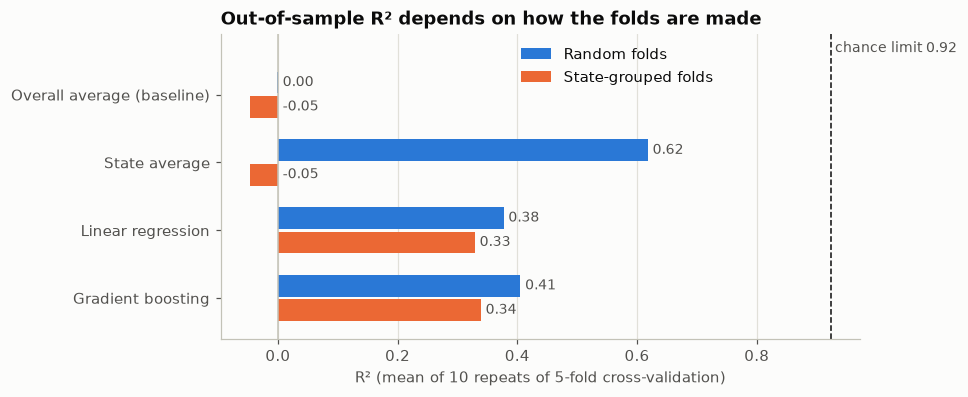

In [40]:
# Task 39: Figure — R² under random folds and state-grouped folds
fig, ax = plt.subplots(figsize=(7.5, 3.6))
names = list(MODELS)[::-1]
for k, (scheme, colour) in enumerate([("State-grouped folds", ORANGE), ("Random folds", BLUE)]):
    s = summary.xs(scheme, level="scheme").reindex(names)
    ypos = np.arange(len(names)) + (k - 0.5) * 0.36
    ax.barh(ypos, s.r2, height=0.32, color=colour, label=scheme)
    for yy, v in zip(ypos, s.r2):
        ax.text(max(v, 0) + 0.008, yy, f"{round(v, 2) + 0:.2f}", va="center", color=MUTED, fontsize=9)
ax.axvline(noise_ceiling, color=INK, linewidth=1, linestyle="--")
ax.text(noise_ceiling, len(names) - 0.42, f" chance limit {noise_ceiling:.2f}", color=MUTED, fontsize=9, va="bottom")
ax.axvline(0, color=AXIS, linewidth=1)
ax.set_yticks(np.arange(len(names)), names)
ax.set_ylim(-0.6, len(names) - 0.1)
ax.set(title="Out-of-sample R² depends on how the folds are made",
       xlabel=f"R² (mean of {N_REPEATS} repeats of {N_FOLDS}-fold cross-validation)")
ax.grid(axis="y", visible=False)
handles, legend_labels = ax.get_legend_handles_labels()
ax.legend(handles[::-1], legend_labels[::-1], frameon=False, loc="upper center", bbox_to_anchor=(0.62, 1.0))
fig.savefig(RESULTS / "fig_04_cv_random_vs_grouped.png")
plt.show()

In [41]:
# Task 40: Test H3 — is the grouped score lower than the random score in every repeat?
wide = cv.pivot_table(index=["model", "repeat"], columns="scheme", values="r2")
gap = (wide["Random folds"] - wide["State-grouped folds"]).groupby("model")
h3 = pd.DataFrame({"mean_r2_drop": gap.mean().round(3),
                   "repeats_with_drop": gap.apply(lambda g: int((g > 0).sum()))})
h3.reindex(list(MODELS))

,mean_r2_drop,repeats_with_drop
model,,
Overall average (baseline),0.046,10
State average,0.665,10
Linear regression,0.048,10
Gradient boosting,0.066,10


In [42]:
# Task 41: Define the state-grouped R² used by every check
def grouped_r2(data, features, target):
    X, y, st = data[features].values, data[target].values * 100, data.state.values
    model = HistGradientBoostingRegressor(max_depth=3, learning_rate=0.05, max_iter=200, random_state=SEED)
    scores = []
    for repeat in range(N_REPEATS):
        order = np.random.default_rng(SEED + repeat).permutation(np.unique(st))
        pred = np.empty(len(y))
        for chunk in np.array_split(order, N_FOLDS):
            test = np.isin(st, chunk)
            pred[test] = model.fit(X[~test], y[~test]).predict(X[test])
        scores.append(r2_score(y, pred))
    return np.mean(scores)

sens = []

In [43]:
# Task 42: Check 0 — main analysis (reference)
sens.append({"check": "Main analysis", "counties": len(main),
             "grouped_r2": grouped_r2(main, FEATURES, "high_share")})
sens[-1]

{'check': 'Main analysis',
 'counties': 2674,
 'grouped_r2': np.float64(0.33872411288094206)}

In [44]:
# Task 43: Check 1 — without the female share, which keeps more small counties
no_sex = [f for f in FEATURES if f != "female_share"]
wider = df.dropna(subset=["high_share"] + no_sex)
sens.append({"check": "Without female share, larger sample", "counties": len(wider),
             "grouped_r2": grouped_r2(wider, no_sex, "high_share")})
sens[-1]

{'check': 'Without female share, larger sample',
 'counties': 2923,
 'grouped_r2': np.float64(0.29131419566363376)}

In [45]:
# Task 44: Check 2 — only counties with 500 or more recipients (less sampling noise)
big = main[main.total >= 500]
sens.append({"check": "Only counties with 500+ recipients", "counties": len(big),
             "grouped_r2": grouped_r2(big, FEATURES, "high_share")})
sens[-1]

{'check': 'Only counties with 500+ recipients',
 'counties': 1638,
 'grouped_r2': np.float64(0.3565409833062491)}

In [46]:
# Task 45: Check 3 — outcome changed to the share rated 100%
full_ok = main.dropna(subset=["full_share"])
sens.append({"check": "Outcome = share rated 100%", "counties": len(full_ok),
             "grouped_r2": grouped_r2(full_ok, FEATURES, "full_share")})
sens[-1]

{'check': 'Outcome = share rated 100%',
 'counties': 2674,
 'grouped_r2': np.float64(0.35662267544152515)}

In [47]:
# Task 46: Table of the sensitivity checks
sens_table = pd.DataFrame(sens).set_index("check").round(3)
sens_table.to_csv(RESULTS / "table_08_sensitivity.csv")
sens_table

,counties,grouped_r2
check,,
Main analysis,2674,0.339
"Without female share, larger sample",2923,0.291
Only counties with 500+ recipients,1638,0.357
Outcome = share rated 100%,2674,0.357


In [48]:
# Task 47: Collect the headline numbers used in the README
score = lambda model, scheme, col="r2": summary.loc[(model, scheme), col]
headline = pd.Series({
    "counties in file": len(df),
    "counties in main sample": len(main),
    "main sample share of county recipients": round(main.total.sum() / df.total.sum(), 4),
    "pooled high-rating share": round(national, 4),
    "county share p5": round(q[0.05], 4), "county share median": round(q[0.5], 4), "county share p95": round(q[0.95], 4),
    "observed SD (points)": round(np.sqrt(observed_var) * 100, 2),
    "chance SD (points)": round(np.sqrt(chance_var) * 100, 2),
    "variance not due to chance": round(noise_ceiling, 3),
    "variance between states": round(between, 3),
    "lowest state": f"{by_state.index[0]} {by_state.high_share.iloc[0]:.1%}",
    "highest state": f"{by_state.index[-1]} {by_state.high_share.iloc[-1]:.1%}",
})

In [49]:
# Task 47b: Add the prediction scores and save
headline = pd.concat([headline, pd.Series({
    "R2 gradient boosting, random folds": score("Gradient boosting", "Random folds"),
    "R2 gradient boosting, state-grouped folds": score("Gradient boosting", "State-grouped folds"),
    "R2 linear, state-grouped folds": score("Linear regression", "State-grouped folds"),
    "R2 state average, random folds": score("State average", "Random folds"),
    "MAE gradient boosting, state-grouped (points)": score("Gradient boosting", "State-grouped folds", "mae"),
    "MAE baseline, state-grouped (points)": score("Overall average (baseline)", "State-grouped folds", "mae"),
})])
headline.to_csv(RESULTS / "table_09_headline_numbers.csv", header=["value"])
headline

counties in file                                                 3144
counties in main sample                                          2674
main sample share of county recipients                         0.9942
pooled high-rating share                                       0.5859
county share p5                                                0.3954
county share median                                            0.5584
county share p95                                               0.6622
observed SD (points)                                              8.1
chance SD (points)                                               2.23
variance not due to chance                                      0.924
variance between states                                         0.633
lowest state                                          Minnesota 37.9%
highest state                                    North Carolina 66.0%
R2 gradient boosting, random folds                              0.405
R2 gradient boosting

In [50]:
# Task 48: Record the library versions
import sklearn, scipy, matplotlib
print("numpy", np.__version__, "| pandas", pd.__version__, "| scipy", scipy.__version__,
      "| scikit-learn", sklearn.__version__, "| matplotlib", matplotlib.__version__)

numpy 2.4.6 | pandas 3.1.1 | scipy 1.17.1 | scikit-learn 1.9.1 | matplotlib 3.11.2


In [51]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.model_selection import KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

DATA_FILE = Path("../data/raw/Disability.csv")
RESULTS = Path("../results")
SEED, N_REPEATS, N_FOLDS, N_BOOT = 42, 10, 5, 2000
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#8a8a85"

In [52]:
raw = pd.read_csv(DATA_FILE, dtype=str)
raw.columns = ["fips", "state", "county", "total", "r0_20", "r30_40", "r50_60", "r70_90", "r100",
               "age_17_44", "age_45_64", "age_65_plus", "male", "female"]
COUNTS = list(raw.columns[3:])
for c in COUNTS:
    raw[c] = pd.to_numeric(raw[c].str.replace(",", ""), errors="coerce")
df = raw[~raw.fips.isin(["72000", "88888", "00000", "Unknown"])].copy()
print(f"{len(df):,} counties, {df.state.nunique()} states | duplicate FIPS: {df.fips.duplicated().sum()}"
      f" | duplicate rows: {df.duplicated().sum()}")

3,144 counties, 51 states | duplicate FIPS: 0 | duplicate rows: 0


In [53]:
df["high"] = df.r70_90 + df.r100
df["high_share"] = df.high / df.total
df["young_share"] = df.age_17_44 / df.total
df["older_share"] = df.age_65_plus / df.total
df["female_share"] = df.female / df.total
df["log_total"] = np.log10(df.total)
FEATURES = ["young_share", "older_share", "female_share", "log_total"]
main = df.dropna(subset=["high_share"] + FEATURES).reset_index(drop=True)
df["in_main"] = df.fips.isin(main.fips)
print(f"Main sample: {len(main):,} of {len(df):,} counties in {main.state.nunique()} states")

Main sample: 2,674 of 3,144 counties in 51 states


In [54]:
X_all = main[FEATURES].values
y_all = main.high_share.values * 100          # percentage points, as in the first notebook
state_all = main.state.values
WEIGHTS = {"unweighted": np.ones(len(main)), "recipient-weighted": main.total.values.astype(float)}

def metrics(pred, w):
    e = y_all - pred
    ybar = np.average(y_all, weights=w)
    return {"r2": 1 - np.sum(w * e**2) / np.sum(w * (y_all - ybar) ** 2),
            "rmse": np.sqrt(np.average(e**2, weights=w)), "mae": np.average(np.abs(e), weights=w)}

print("Total recipients (weights) summary:", main.total.describe()[["min", "50%", "max"]].to_dict())

Total recipients (weights) summary: {'min': 62.0, '50%': 710.5, 'max': 98159.0}


In [55]:
def random_folds(repeat):
    return [t for _, t in KFold(N_FOLDS, shuffle=True, random_state=SEED + repeat).split(X_all)]

def state_folds(repeat):
    order = np.random.default_rng(SEED + repeat).permutation(np.unique(state_all))
    return [np.flatnonzero(np.isin(state_all, chunk)) for chunk in np.array_split(order, N_FOLDS)]

FOLDS = {"Random folds": [random_folds(r) for r in range(N_REPEATS)],
         "State-grouped folds": [state_folds(r) for r in range(N_REPEATS)]}
print({k: [len(t) for t in v[0]] for k, v in FOLDS.items()})

{'Random folds': [535, 535, 535, 535, 534], 'State-grouped folds': [554, 429, 595, 552, 544]}


In [56]:
MODELS = {
    "Overall average (baseline)": DummyRegressor(),
    "Linear regression": make_pipeline(StandardScaler(), LinearRegression()),
    "Gradient boosting": HistGradientBoostingRegressor(max_depth=3, learning_rate=0.05, max_iter=200, random_state=SEED),
}

def oof_predict(model, folds, X=X_all):
    pred = np.empty(len(y_all))
    for test in folds:
        train = np.setdiff1d(np.arange(len(y_all)), test)
        pred[test] = model.fit(X[train], y_all[train]).predict(X[test])
    return pred

print(list(MODELS))

['Overall average (baseline)', 'Linear regression', 'Gradient boosting']


In [57]:
OOF = {(s, m): np.array([oof_predict(MODELS[m], FOLDS[s][r]) for r in range(N_REPEATS)])
       for s in FOLDS for m in MODELS}
oof_table = pd.DataFrame({f"{s}|{m}|rep{r}": P[r] for (s, m), P in OOF.items() for r in range(N_REPEATS)}, index=main.fips)
oof_table.round(4).to_csv(RESULTS / "table_10_oof_predictions.csv")
print({k: v.shape for k, v in list(OOF.items())[:2]}, "| saved columns:", oof_table.shape[1])

{('Random folds', 'Overall average (baseline)'): (10, 2674), ('Random folds', 'Linear regression'): (10, 2674)} | saved columns: 60


In [58]:
def score_table(store):
    rows = []
    for (design, model), P in store.items():
        for wname, w in WEIGHTS.items():
            r = pd.DataFrame([metrics(p, w) for p in P])
            rows.append({"design": design, "model": model, "weighting": wname, "r2": r.r2.mean(), "r2_min": r.r2.min(),
                         "r2_max": r.r2.max(), "rmse": r.rmse.mean(), "mae": r.mae.mean()})
    return pd.DataFrame(rows)

cv = score_table(OOF)
ref = pd.read_csv(RESULTS / "table_07_cv_summary.csv").set_index(["model", "scheme"]).r2
mine = cv[cv.weighting == "unweighted"].set_index(["model", "design"]).r2
repro = pd.DataFrame({"this_notebook": mine, "first_notebook": ref.reindex(mine.index)})
repro["difference"] = repro.this_notebook - repro.first_notebook
repro.round(4).to_csv(RESULTS / "table_10_cv_reproduction.csv")
repro.round(4)

,,this_notebook,first_notebook,difference
model,design,,,
Overall average (baseline),Random folds,-0.0012,-0.001,-0.0002
Linear regression,Random folds,0.3773,0.377,0.0003
Gradient boosting,Random folds,0.4047,0.405,-0.0003
Overall average (baseline),State-grouped folds,-0.0469,-0.047,0.0001
Linear regression,State-grouped folds,0.3290,0.329,-0.0000
Gradient boosting,State-grouped folds,0.3387,0.339,-0.0003


In [59]:
states = np.unique(state_all)
rows_of = {s: np.flatnonzero(state_all == s) for s in states}
rng = np.random.default_rng(SEED)
boot = [rng.choice(states, len(states)) for _ in range(N_BOOT)]
KEYS = [("Random folds", "Gradient boosting"), ("State-grouped folds", "Gradient boosting"),
        ("State-grouped folds", "Linear regression")]

def pooled_r2(P, rows):
    y = y_all[rows]
    return np.mean([1 - ((y - p[rows]) ** 2).sum() / ((y - y.mean()) ** 2).sum() for p in P])

def three_numbers(draw):
    rows = np.concatenate([rows_of[s] for s in draw])
    label = np.repeat(np.arange(len(draw)), [len(rows_of[s]) for s in draw])
    y = y_all[rows]
    n_k, sum_k = np.bincount(label), np.bincount(label, y)
    eta2 = (n_k * (sum_k / n_k - y.mean()) ** 2).sum() / ((y - y.mean()) ** 2).sum()
    gb_rand, gb_grp, lin_grp = (pooled_r2(OOF[k], rows) for k in KEYS)
    return [gb_rand - gb_grp, gb_grp - lin_grp, eta2]

In [60]:
point = three_numbers(states)
draws = np.array([three_numbers(d) for d in boot])
boot_table = pd.DataFrame({"estimate": point, "ci_low": np.percentile(draws, 2.5, axis=0),
                           "ci_high": np.percentile(draws, 97.5, axis=0)},
                          index=["GB R2 gap: random minus grouped", "Grouped R2: GB minus linear",
                                 "Between-state share of variance (eta-squared)"])
boot_table.round(3).to_csv(RESULTS / "table_11_bootstrap_ci.csv")
boot_table.round(3)

,estimate,ci_low,ci_high
GB R2 gap: random minus grouped,0.066,0.049,0.088
Grouped R2: GB minus linear,0.010,-0.032,0.048
Between-state share of variance (eta-squared),0.633,0.499,0.712


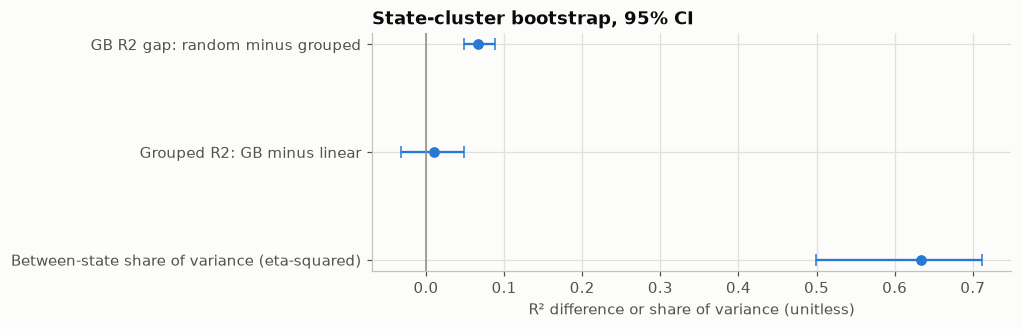

In [61]:
fig, ax = plt.subplots(figsize=(7.5, 2.8))
ypos = np.arange(len(boot_table))[::-1]
err = [boot_table.estimate - boot_table.ci_low, boot_table.ci_high - boot_table.estimate]
ax.errorbar(boot_table.estimate, ypos, xerr=err, fmt="o", color=BLUE, capsize=4)
ax.axvline(0, color=GREY, linewidth=1)
ax.set_yticks(ypos, boot_table.index)
ax.set(title="State-cluster bootstrap, 95% CI", xlabel="R² difference or share of variance (unitless)")
fig.savefig(RESULTS / "fig_05_bootstrap_ci.png", dpi=150, bbox_inches="tight")
plt.show()

In [62]:
def fold_r2(model):
    P = OOF[("State-grouped folds", model)]
    return np.array([r2_score(y_all[t], P[r][t]) for r in range(N_REPEATS) for t in FOLDS["State-grouped folds"][r]])

def nb_test(a, b):
    d = a - b
    n, se = len(d), np.sqrt((1 / len(d) + 1 / (N_FOLDS - 1)) * d.var(ddof=1))
    p = 2 * stats.t.sf(abs(d.mean() / se), df=n - 1)
    half = stats.t.ppf(0.975, n - 1) * se
    return {"n_fold_scores": n, "mean_diff": d.mean(), "ci_low": d.mean() - half, "ci_high": d.mean() + half, "p_raw": p}

fs = {m: fold_r2(m) for m in MODELS}
nb = pd.DataFrame({"GB minus baseline": nb_test(fs["Gradient boosting"], fs["Overall average (baseline)"]),
                   "GB minus linear": nb_test(fs["Gradient boosting"], fs["Linear regression"])}).T
p = nb.p_raw.values
holm = np.minimum(1, np.maximum.accumulate((len(p) - np.arange(len(p))) * np.sort(p)))
nb["p_holm"] = holm[np.argsort(np.argsort(p))]
nb.round(4).to_csv(RESULTS / "table_12_nadeau_bengio.csv")
nb.round(4)

,n_fold_scores,mean_diff,ci_low,ci_high,p_raw,p_holm
GB minus baseline,50.0,0.4097,0.2137,0.6058,0.0001,0.0002
GB minus linear,50.0,0.0097,-0.0399,0.0593,0.6954,0.6954


In [63]:
cv.round(3).to_csv(RESULTS / "table_13_weighted_vs_unweighted.csv", index=False)
cv.pivot_table(index=["design", "model"], columns="weighting", values=["r2", "rmse", "mae"]).round(3)

mae             \
weighting                                      recipient-weighted unweighted   
design              model                                                      
Random folds        Gradient boosting                       4.305      4.998   
                    Linear regression                       4.434      5.111   
                    Overall average (baseline)              6.977      6.373   
State-grouped folds Gradient boosting                       4.529      5.249   
                    Linear regression                       4.613      5.304   
                    Overall average (baseline)              7.129      6.531   

                                                               r2             \
weighting                                      recipient-weighted unweighted   
design              model                                                      
Random folds        Gradient boosting                       0.525      0.405   
                    Linear regression                       0.510      0.377   
                    Overall average (baseline)             -0.226     -0.001   
State-grouped folds Gradient boosting                       0.473      0.339   
                    Linear regression                       0.469      0.329   
                    Overall average (baseline)             -0.274     -0.047   

                                                             rmse             
weighting                                      recipient-weighted unweighted  
design              model                                                     
Random folds        Gradient boosting                       5.403      6.252  
                    Linear regression                       5.489      6.394  
                    Overall average (baseline)              8.681      8.108  
State-grouped folds Gradient boosting                       5.692      6.589  
                    Linear regression                       5.708      6.637  
                    Overall average (baseline)              8.847      8.290

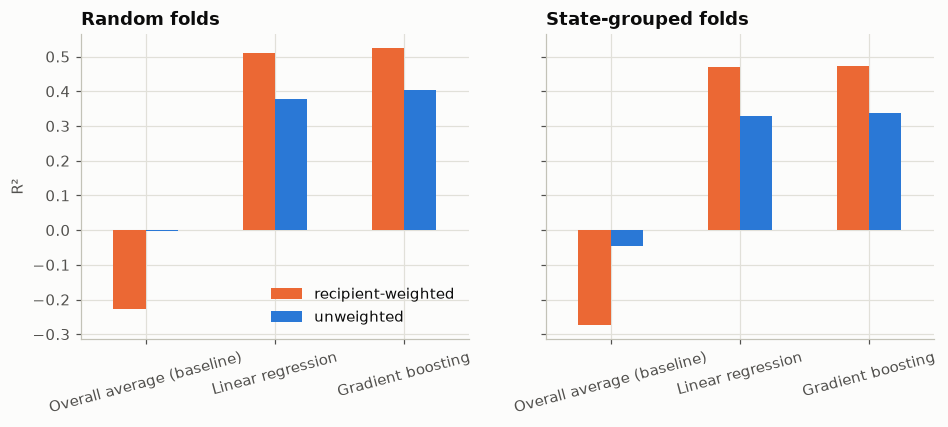

In [64]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, scheme in zip(axes, FOLDS):
    t = cv[cv.design == scheme].pivot(index="model", columns="weighting", values="r2").loc[list(MODELS)]
    t.plot.bar(ax=ax, color=[ORANGE, BLUE], rot=15, legend=False)
    ax.set(title=scheme, xlabel="", ylabel="R²")
axes[0].legend(frameon=False)
fig.savefig(RESULTS / "fig_06_weighted_vs_unweighted_r2.png", dpi=150, bbox_inches="tight")
plt.show()

In [65]:
REGION_OF_PREFIX = {}
for region, prefixes in {
    "Northeast": "09 23 25 33 44 50 34 36 42", "Midwest": "17 18 26 39 55 19 20 27 29 31 38 46",
    "South": "10 11 12 13 24 37 45 51 54 01 21 28 47 05 22 40 48", "West": "04 08 16 30 32 35 49 56 02 06 15 41 53"}.items():
    REGION_OF_PREFIX.update({p: region for p in prefixes.split()})
main["region"] = main.fips.str[:2].map(REGION_OF_PREFIX)
region_map = main.assign(prefix=main.fips.str[:2]).groupby("state").agg(fips_prefix=("prefix", "first"), region=("region", "first"))
region_map.sort_values(["region", "fips_prefix"]).to_csv(RESULTS / "table_14_fips_region_map.csv")
print("Counties without a region:", main.region.isna().sum(), "| states per region:", region_map.region.value_counts().to_dict())
region_map.sort_values(["region", "fips_prefix"])

Counties without a region: 0 | states per region: {'South': 17, 'West': 13, 'Midwest': 12, 'Northeast': 9}


,fips_prefix,region
state,,
Illinois,17,Midwest
Indiana,18,Midwest
Iowa,19,Midwest
Kansas,20,Midwest
Michigan,26,Midwest
Minnesota,27,Midwest
Missouri,29,Midwest
Nebraska,31,Midwest
North Dakota,38,Midwest


In [66]:
BLOCKS = {"Leave-one-state-out": [rows_of[s] for s in states],
          "Region-blocked": [np.flatnonzero(main.region.values == r) for r in sorted(main.region.unique())]}
BLOCK = {(d, m): oof_predict(MODELS[m], BLOCKS[d])[None] for d in BLOCKS for m in MODELS}
print({d: [len(b) for b in v] if len(v) < 10 else f"{len(v)} blocks" for d, v in BLOCKS.items()})

{'Leave-one-state-out': '51 blocks', 'Region-blocked': [824, 213, 1274, 363]}


In [67]:
blocked = score_table(BLOCK)
blocked.round(3).to_csv(RESULTS / "table_15_loso_region_pooled.csv", index=False)
blocked.pivot_table(index=["design", "model"], columns="weighting", values=["r2", "rmse"]).round(3)

r2             \
weighting                                      recipient-weighted unweighted   
design              model                                                      
Leave-one-state-out Gradient boosting                       0.473      0.345   
                    Linear regression                       0.469      0.333   
                    Overall average (baseline)             -0.269     -0.040   
Region-blocked      Gradient boosting                       0.223     -0.132   
                    Linear regression                       0.309     -0.097   
                    Overall average (baseline)             -1.129     -0.750   

                                                             rmse             
weighting                                      recipient-weighted unweighted  
design              model                                                     
Leave-one-state-out Gradient boosting                       5.689      6.560  
                    Linear regression                       5.713      6.615  
                    Overall average (baseline)              8.829      8.263  
Region-blocked      Gradient boosting                       6.912      8.621  
                    Linear regression                       6.516      8.487  
                    Overall average (baseline)             11.438     10.719

In [68]:
def error_table(design, group):
    rows = []
    for g in np.unique(group):
        i = group == g
        row = {"group": g, "counties": i.sum(), "recipients": int(WEIGHTS["recipient-weighted"][i].sum())}
        for m in MODELS:
            e = BLOCK[(design, m)][0][i] - y_all[i]
            row[m + " | rmse"], row[m + " | bias"] = np.sqrt((e**2).mean()), e.mean()
        rows.append(row)
    return pd.DataFrame(rows).set_index("group").sort_values("Gradient boosting | rmse")

loso_state = error_table("Leave-one-state-out", state_all)
loso_state.round(2).to_csv(RESULTS / "table_16_loso_per_state_error.csv")
pd.concat([loso_state.head(5), loso_state.tail(5)]).round(2)

,counties,recipients,Overall average (baseline) | rmse,Overall average (baseline) | bias,Linear regression | rmse,Linear regression | bias,Gradient boosting | rmse,Gradient boosting | bias
group,,,,,,,,
Delaware,3,19494,3.70,-2.57,2.64,0.95,2.36,2.31
Massachusetts,13,76527,5.98,4.77,2.75,-0.30,2.94,-0.85
Maine,16,34310,4.36,-3.18,4.24,-2.99,3.64,-2.39
Kansas,47,51166,5.77,-0.92,3.56,0.17,3.78,-0.11
Michigan,83,142220,4.98,2.79,3.72,-0.39,3.86,-0.74
Alaska,12,25316,8.66,3.36,14.42,11.00,9.89,7.58
Nebraska,42,45486,18.07,17.02,12.02,11.38,9.95,8.87
Minnesota,73,105058,18.80,18.04,12.16,11.23,10.94,9.47
Indiana,89,115775,13.00,11.55,10.82,9.40,11.12,9.73


In [69]:
region_err = error_table("Region-blocked", main.region.values)
region_err.round(2).to_csv(RESULTS / "table_17_region_blocked_error.csv")
region_err.round(2)

,counties,recipients,Overall average (baseline) | rmse,Overall average (baseline) | bias,Linear regression | rmse,Linear regression | bias,Gradient boosting | rmse,Gradient boosting | bias
group,,,,,,,,
Northeast,213,600157,4.98,1.67,4.74,-0.16,4.82,0.18
West,363,1389892,6.17,1.89,6.78,0.94,6.67,1.44
South,1274,3125827,11.13,-9.83,8.35,-6.57,8.37,-6.74
Midwest,824,1096956,12.58,9.88,10.00,7.33,10.36,7.60


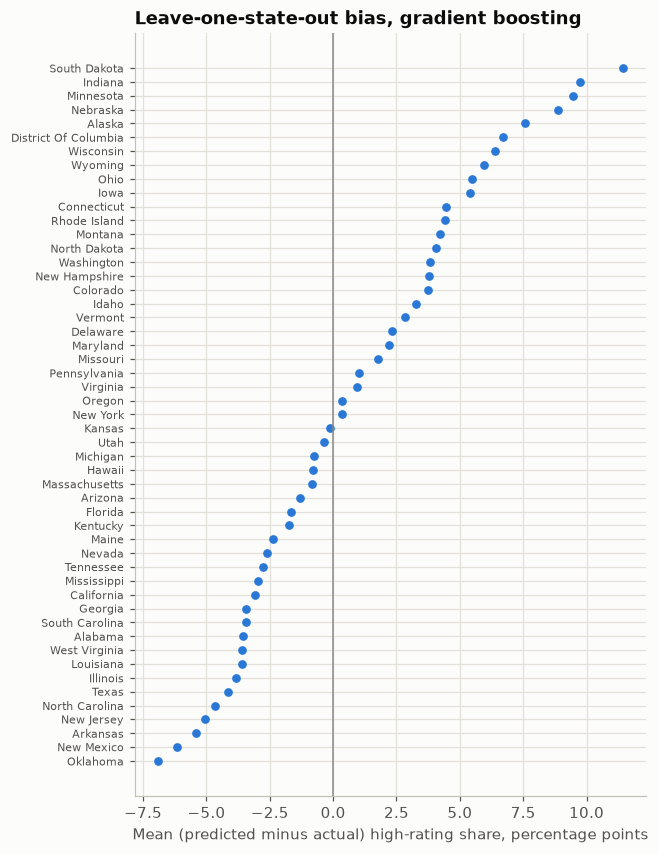

In [70]:
bias = loso_state["Gradient boosting | bias"].sort_values()
fig, ax = plt.subplots(figsize=(6, 9))
ax.scatter(bias, np.arange(len(bias)), s=22, color=BLUE)
ax.axvline(0, color=GREY, linewidth=1)
ax.set_yticks(np.arange(len(bias)), bias.index, fontsize=7)
ax.set(title="Leave-one-state-out bias, gradient boosting", xlabel="Mean (predicted minus actual) high-rating share, percentage points")
fig.savefig(RESULTS / "fig_07_loso_bias_per_state.png", dpi=150, bbox_inches="tight")
plt.show()

In [71]:
D = pd.get_dummies(main.state).values.astype(float)
FE_DESIGNS = {"State only (one-hot)": D, "Features only": X_all, "Features + state one-hot": np.hstack([X_all, D])}
FE = {(name, "Linear regression"): np.array([oof_predict(LinearRegression(), FOLDS["Random folds"][r], Xd)
                                            for r in range(N_REPEATS)]) for name, Xd in FE_DESIGNS.items()}
fe_table = score_table(FE)
fe_table.round(3).to_csv(RESULTS / "table_18_fixed_effects_cv.csv", index=False)
fe_table.pivot_table(index="design", columns="weighting", values=["r2", "rmse"]).round(3)

r2                          rmse  \
weighting                recipient-weighted unweighted recipient-weighted   
design                                                                      
Features + state one-hot              0.756      0.718              3.874   
Features only                         0.510      0.377              5.489   
State only (one-hot)                  0.414      0.618              6.000   

                                     
weighting                unweighted  
design                               
Features + state one-hot      4.303  
Features only                 6.394  
State only (one-hot)          5.007

In [72]:
def std_coefs(rows, within):
    d = main.iloc[rows]
    Xs, y = (d[FEATURES] - d[FEATURES].mean()) / d[FEATURES].std(), d.high_share * 100
    if within:
        Xs, y = Xs - Xs.groupby(d.state).transform("mean"), y - y.groupby(d.state).transform("mean")
    return LinearRegression().fit(Xs, y).coef_

all_rows = np.arange(len(main))
boot_rows = [np.concatenate([rows_of[s] for s in draw]) for draw in boot]
coef = {}
for name, within in [("Pooled", False), ("Within-state", True)]:
    b = np.array([std_coefs(r, within) for r in boot_rows])
    coef[name] = pd.DataFrame({"points_per_sd": std_coefs(all_rows, within), "ci_low": np.percentile(b, 2.5, axis=0),
                               "ci_high": np.percentile(b, 97.5, axis=0)}, index=FEATURES)

points_per_sd  ci_low  ci_high
model        feature                                     
Pooled       young_share           -3.52   -4.85    -2.16
             older_share           -5.70   -7.98    -3.30
             female_share           1.96    0.98     3.11
             log_total              0.03   -0.68     0.89
Within-state young_share           -1.88   -2.59    -1.17
             older_share           -3.16   -3.91    -2.34
             female_share           1.27    0.80     1.68
             log_total              0.29   -0.14     0.70

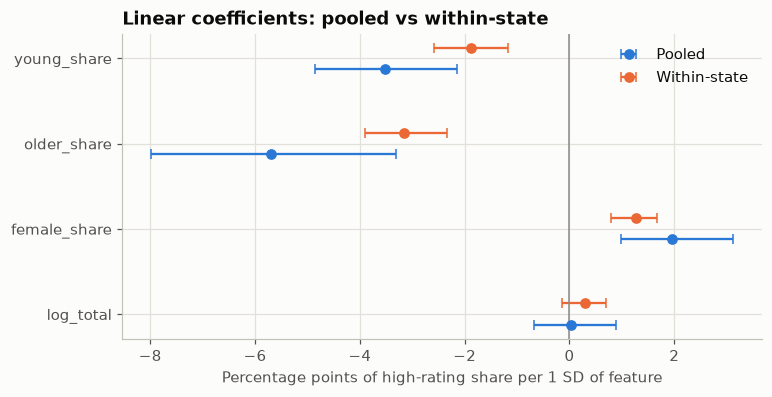

In [73]:
coef_table = pd.concat(coef, names=["model", "feature"]).round(2)
coef_table.to_csv(RESULTS / "table_19_within_state_coefficients.csv")
fig, ax = plt.subplots(figsize=(7.5, 3.6))
for k, (name, colour) in enumerate([("Pooled", BLUE), ("Within-state", ORANGE)]):
    c = coef[name]
    ax.errorbar(c.points_per_sd, np.arange(4)[::-1] + (k - 0.5) * 0.25, fmt="o", color=colour, label=name, capsize=3,
                xerr=[c.points_per_sd - c.ci_low, c.ci_high - c.points_per_sd])
ax.axvline(0, color=GREY, linewidth=1)
ax.set_yticks(np.arange(4)[::-1], FEATURES)
ax.set(title="Linear coefficients: pooled vs within-state", xlabel="Percentage points of high-rating share per 1 SD of feature")
ax.legend(frameon=False)
fig.savefig(RESULTS / "fig_08_pooled_vs_within_coefficients.png", dpi=150, bbox_inches="tight")
coef_table

In [74]:
excl = df[~df.in_main & df.high_share.notna()]
groups = pd.Series({"in main sample": df.in_main.sum(), "excluded, outcome computable": len(excl),
                    "excluded, outcome not computable": (~df.in_main & df.high_share.isna()).sum()})
print("Sum of groups:", groups.sum(), "| all counties:", len(df))
print("Excluded-with-outcome counties with all four features buildable:", excl[FEATURES].notna().all(axis=1).sum())
print("Blank features among excluded-with-outcome:\n", excl[FEATURES].isna().sum().to_string())
groups.to_frame("counties")

Sum of groups: 3144 | all counties: 3144
Excluded-with-outcome counties with all four features buildable: 0
Blank features among excluded-with-outcome:
 young_share      38
older_share       0
female_share    285
log_total         0


,counties
in main sample,2674
"excluded, outcome computable",287
"excluded, outcome not computable",183


In [75]:
state_share = main.groupby("state").high.sum() / main.groupby("state").total.sum()
expected = (excl.total * excl.state.map(state_share)).sum() / excl.total.sum()
sel = pd.DataFrame({
    "counties": [len(main), len(excl)],
    "recipients": [main.total.sum(), excl.total.sum()],
    "pooled_high_share": [main.high.sum() / main.total.sum(), excl.high.sum() / excl.total.sum()],
    "median_recipients": [main.total.median(), excl.total.median()]}, index=["main sample", "excluded (outcome computable)"])
sel["expected_given_its_states"] = [np.nan, expected]
print("Excluded counties whose state has no main-sample county:", (~excl.state.isin(state_share.index)).sum())
sel.round(4).to_csv(RESULTS / "table_20_selection_check.csv")
sel.round(4)

Excluded counties whose state has no main-sample county: 0


,counties,recipients,pooled_high_share,median_recipients,expected_given_its_states
main sample,2674,6212832.0,0.5859,710.5,NaN
excluded (outcome computable),287,29749.0,0.4979,94.0,0.5472


In [76]:
import matplotlib
import scipy
import sklearn

print("numpy", np.__version__, "| pandas", pd.__version__, "| scipy", scipy.__version__,
      "| scikit-learn", sklearn.__version__, "| matplotlib", matplotlib.__version__)

numpy 2.4.6 | pandas 3.1.1 | scipy 1.17.1 | scikit-learn 1.9.1 | matplotlib 3.11.2


In [77]:
"""
PRE-SPECIFIED PLAN (fixed before any new model was run; pre-approved by the caller, not chosen by the tutor)
Question: can out-of-state prediction of the county high-rating share be improved over untuned GB / linear, and is any gain real?
Data: Disability.csv, same cleaning, outcome, 4 features, main sample, seed and outer folds as notebook 02 (5 folds x 10 repeats, state-grouped).
Primary metric: grouped OOF R2 and RMSE, counties equal; recipient-weighted R2/RMSE alongside.
Candidates (12 grid points each, inner GroupKFold(3) over outer-training states only): Ridge, Ridge+poly2, RandomForest, HistGB,
  Ridge and HistGB fitted with recipient weights, ensemble of the inner-CV-best linear and best tree. References: baseline, untuned linear, untuned GB.
Improvement rule: 95% state-cluster bootstrap CI (2000 resamples, stored OOF, no refit) of the paired R2 difference vs the better existing model
  excludes 0 (lower bound > 0). Also reported: Nadeau-Bengio t-test on 50 fold scores with Holm over all new-vs-reference comparisons.
No features from the outcome or other rating bands; no tuning on outer test states.
Extras: (g) LOSO nearest-neighbour distance vs state RMSE (Spearman); (h) MixedLM only if statsmodels is already installed.
"""

'\nPRE-SPECIFIED PLAN (fixed before any new model was run; pre-approved by the caller, not chosen by the tutor)\nQuestion: can out-of-state prediction of the county high-rating share be improved over untuned GB / linear, and is any gain real?\nData: Disability.csv, same cleaning, outcome, 4 features, main sample, seed and outer folds as notebook 02 (5 folds x 10 repeats, state-grouped).\nPrimary metric: grouped OOF R2 and RMSE, counties equal; recipient-weighted R2/RMSE alongside.\nCandidates (12 grid points each, inner GroupKFold(3) over outer-training states only): Ridge, Ridge+poly2, RandomForest, HistGB,\n  Ridge and HistGB fitted with recipient weights, ensemble of the inner-CV-best linear and best tree. References: baseline, untuned linear, untuned GB.\nImprovement rule: 95% state-cluster bootstrap CI (2000 resamples, stored OOF, no refit) of the paired R2 difference vs the better existing model\n  excludes 0 (lower bound > 0). Also reported: Nadeau-Bengio t-test on 50 fold score

In [78]:
import importlib.util
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from joblib import Parallel, delayed
from scipy import stats
from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import r2_score
from sklearn.model_selection import GroupKFold, ParameterGrid
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

In [79]:
DATA_FILE = Path("../data/raw/Disability.csv")
RESULTS = Path("../results")
SEED, N_REPEATS, N_FOLDS, N_BOOT = 42, 10, 5, 2000
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#8a8a85"
raw = pd.read_csv(DATA_FILE, dtype=str)
raw.columns = ["fips", "state", "county", "total", "r0_20", "r30_40", "r50_60", "r70_90", "r100",
               "age_17_44", "age_45_64", "age_65_plus", "male", "female"]
for c in raw.columns[3:]:
    raw[c] = pd.to_numeric(raw[c].str.replace(",", ""), errors="coerce")
df = raw[~raw.fips.isin(["72000", "88888", "00000", "Unknown"])].copy()
print(f"{len(df):,} counties, {df.state.nunique()} states | duplicate FIPS: {df.fips.duplicated().sum()}"
      f" | duplicate rows: {df.duplicated().sum()}")

3,144 counties, 51 states | duplicate FIPS: 0 | duplicate rows: 0


In [80]:
df["high_share"] = (df.r70_90 + df.r100) / df.total
df["young_share"] = df.age_17_44 / df.total
df["older_share"] = df.age_65_plus / df.total
df["female_share"] = df.female / df.total
df["log_total"] = np.log10(df.total)
FEATURES = ["young_share", "older_share", "female_share", "log_total"]
main = df.dropna(subset=["high_share"] + FEATURES).reset_index(drop=True)
X_all = main[FEATURES].values
y_all = main.high_share.values * 100          # percentage points
state_all = main.state.values
TOTAL = main.total.values.astype(float)
WEIGHTS = {"unweighted": np.ones(len(main)), "recipient-weighted": TOTAL}
print(f"Main sample: {len(main):,} counties in {main.state.nunique()} states")

Main sample: 2,674 counties in 51 states


In [81]:
def state_folds(repeat):
    order = np.random.default_rng(SEED + repeat).permutation(np.unique(state_all))
    return [np.flatnonzero(np.isin(state_all, chunk)) for chunk in np.array_split(order, N_FOLDS)]

STATE_FOLDS = [state_folds(r) for r in range(N_REPEATS)]
MODELS = {
    "Overall average (baseline)": DummyRegressor(),
    "Linear regression": make_pipeline(StandardScaler(), LinearRegression()),
    "Gradient boosting": HistGradientBoostingRegressor(max_depth=3, learning_rate=0.05, max_iter=200, random_state=SEED),
}

def oof_predict(model, folds):
    pred = np.empty(len(y_all))
    for test in folds:
        train = np.setdiff1d(np.arange(len(y_all)), test)
        pred[test] = model.fit(X_all[train], y_all[train]).predict(X_all[test])
    return pred

print([len(t) for t in STATE_FOLDS[0]])
OOF_REF = {m: np.array([oof_predict(MODELS[m], STATE_FOLDS[r]) for r in range(N_REPEATS)]) for m in MODELS}

[554, 429, 595, 552, 544]


In [82]:
def metrics(pred, w):
    e = y_all - pred
    ybar = np.average(y_all, weights=w)
    return {"r2": 1 - np.sum(w * e**2) / np.sum(w * (y_all - ybar) ** 2), "rmse": np.sqrt(np.average(e**2, weights=w))}

first = pd.read_csv(RESULTS / "table_07_cv_summary.csv").query("scheme == 'State-grouped folds'").set_index("model").r2
repro = pd.DataFrame({"this_notebook": {m: np.mean([metrics(p, WEIGHTS["unweighted"])["r2"] for p in P]) for m, P in OOF_REF.items()}})
repro["first_notebook"] = first.reindex(repro.index)
repro["difference"] = repro.this_notebook - repro.first_notebook
assert repro.difference.abs().max() < 0.0006, "reference scores NOT reproduced"
repro.round(4)

,this_notebook,first_notebook,difference
Overall average (baseline),-0.0469,-0.047,0.0001
Linear regression,0.3290,0.329,-0.0000
Gradient boosting,0.3387,0.339,-0.0003


In [83]:
PIPES = {
    "ridge": Pipeline([("scale", StandardScaler()), ("model", Ridge())]),
    "poly": Pipeline([("poly", PolynomialFeatures(2, include_bias=False)), ("scale", StandardScaler()), ("model", Ridge())]),
    "rf": Pipeline([("model", RandomForestRegressor(n_estimators=150, random_state=SEED))]),
    "hgb": Pipeline([("model", HistGradientBoostingRegressor(random_state=SEED))]),
}
ALPHAS = np.logspace(-2, 3, 12)
GRIDS = {"ridge": {"model__alpha": ALPHAS}, "poly": {"model__alpha": ALPHAS},
         "rf": {"model__max_depth": [3, 6, 10], "model__min_samples_leaf": [5, 20, 50, 100]},
         "hgb": {"model__max_depth": [2, 3, 5], "model__learning_rate": [0.03, 0.1], "model__max_iter": [100, 300]}}
grid_table = pd.DataFrame({"grid": {k: {p: [round(float(v), 3) for v in vs] for p, vs in g.items()} for k, g in GRIDS.items()},
                           "combinations": {k: len(ParameterGrid(g)) for k, g in GRIDS.items()}})
grid_table.to_csv(RESULTS / "table_21_tuning_grids.csv")
grid_table

,grid,combinations
ridge,"{'model__alpha': ['0.01', '0.028', '0.081', '0...",12
poly,"{'model__alpha': ['0.01', '0.028', '0.081', '0...",12
rf,"{'model__max_depth': ['3.0', '6.0', '10.0'], '...",12
hgb,"{'model__max_depth': ['2.0', '3.0', '5.0'], 'm...",12


In [84]:
def inner_mse(key, params, Xt, yt, wt, inner):
    err, wts = [], []
    for a, b in inner:
        m = clone(PIPES[key]).set_params(**params).fit(Xt[a], yt[a], model__sample_weight=wt[a])
        err.append((yt[b] - m.predict(Xt[b])) ** 2)
        wts.append(wt[b])
    return np.average(np.concatenate(err), weights=np.concatenate(wts))

def tune_fit(key, train, test, weighted):
    Xt, yt = X_all[train], y_all[train]
    wt = TOTAL[train] if weighted else np.ones(len(train))
    inner = list(GroupKFold(3).split(Xt, yt, state_all[train]))
    grid = list(ParameterGrid(GRIDS[key]))
    scores = [inner_mse(key, p, Xt, yt, wt, inner) for p in grid]
    best = grid[int(np.argmin(scores))]
    model = clone(PIPES[key]).set_params(**best).fit(Xt, yt, model__sample_weight=wt)
    return best, min(scores), model.predict(X_all[test])

print("inner folds use states of the outer-training part only; example inner fold sizes:",
      [len(b) for _, b in GroupKFold(3).split(X_all, y_all, state_all)])

inner folds use states of the outer-training part only; example inner fold sizes: [893, 891, 890]


In [85]:
CANDS = {"Ridge (tuned)": ("ridge", False), "Ridge + poly2 (tuned)": ("poly", False),
         "Random forest (tuned)": ("rf", False), "HistGB (tuned)": ("hgb", False),
         "Ridge, recipient-weighted fit": ("ridge", True), "HistGB, recipient-weighted fit": ("hgb", True)}
ENS = "Ensemble: best linear + best tree"

def outer_fold(r, k):
    test = STATE_FOLDS[r][k]
    train = np.setdiff1d(np.arange(len(y_all)), test)
    out = {n: tune_fit(key, train, test, w) for n, (key, w) in CANDS.items()}
    lin = min(["Ridge (tuned)", "Ridge + poly2 (tuned)"], key=lambda n: out[n][1])
    tree = min(["Random forest (tuned)", "HistGB (tuned)"], key=lambda n: out[n][1])
    out[ENS] = ({"linear": lin, "tree": tree}, np.nan, (out[lin][2] + out[tree][2]) / 2)
    return out

t0 = time.time()
results = Parallel(n_jobs=-1)(delayed(outer_fold)(r, k) for r in range(N_REPEATS) for k in range(N_FOLDS))
print(f"{len(results)} outer folds done in {time.time() - t0:.0f} s")

50 outer folds done in 140 s


In [86]:
NEW = list(CANDS) + [ENS]
OOF_NEW = {n: np.zeros((N_REPEATS, len(y_all))) for n in NEW}
chosen = []
for i, res in enumerate(results):
    r, k = divmod(i, N_FOLDS)
    for n in NEW:
        OOF_NEW[n][r][STATE_FOLDS[r][k]] = res[n][2]
        chosen.append({"repeat": r, "fold": k, "candidate": n, "chosen": str(res[n][0]), "inner_mse": res[n][1]})
chosen = pd.DataFrame(chosen)
chosen.round(4).to_csv(RESULTS / "table_22_selected_hyperparameters.csv", index=False)
chosen.groupby("candidate").chosen.value_counts().groupby(level=0).head(2).to_frame("folds")

folds
candidate                         chosen                                                   
Ensemble: best linear + best tree {'linear': 'Ridge + poly2 (tuned)', 'tree': 'Hi...     42
                                  {'linear': 'Ridge + poly2 (tuned)', 'tree': 'Ra...      4
HistGB (tuned)                    {'model__learning_rate': 0.1, 'model__max_depth...     31
                                  {'model__learning_rate': 0.03, 'model__max_dept...     16
HistGB, recipient-weighted fit    {'model__learning_rate': 0.03, 'model__max_dept...     15
                                  {'model__learning_rate': 0.03, 'model__max_dept...     13
Random forest (tuned)             {'model__max_depth': 6, 'model__min_samples_lea...     27
                                  {'model__max_depth': 10, 'model__min_samples_le...     13
Ridge (tuned)                     {'model__alpha': np.float64(15.199110829529332)}       15
                                  {'model__alpha': np.float64(0.01)}                     11
Ridge + poly2 (tuned)             {'model__alpha': np.float64(1.873817422860383)}        16
                                  {'model__alpha': np.float64(5.336699231206307)}         9
Ridge, recipient-weighted fit     {'model__alpha': np.float64(1000.0)}                   48
                                  {'model__alpha': np.float64(0.01)}                      2

In [87]:
ALL = {**OOF_REF, **OOF_NEW}
rows = {}
for name, P in ALL.items():
    u = pd.DataFrame([metrics(p, WEIGHTS["unweighted"]) for p in P])
    w = pd.DataFrame([metrics(p, WEIGHTS["recipient-weighted"]) for p in P])
    rows[name] = {"r2_u": u.r2.mean(), "r2_min": u.r2.min(), "r2_max": u.r2.max(), "rmse_u": u.rmse.mean(),
                  "r2_w": w.r2.mean(), "rmse_w": w.rmse.mean()}
scores = pd.DataFrame(rows).T
scores.round(4).to_csv(RESULTS / "table_23_all_candidates.csv")
pd.DataFrame({f"{n}|rep{r}": P[r] for n, P in ALL.items() for r in range(N_REPEATS)}, index=main.fips).round(3).to_csv(
    RESULTS / "table_24_oof_predictions.csv")
scores.round(3)

,r2_u,r2_min,r2_max,rmse_u,r2_w,rmse_w
Overall average (baseline),-0.047,-0.097,-0.012,8.290,-0.274,8.847
Linear regression,0.329,0.294,0.357,6.637,0.469,5.708
Gradient boosting,0.339,0.308,0.363,6.589,0.473,5.692
Ridge (tuned),0.326,0.292,0.357,6.652,0.471,5.699
Ridge + poly2 (tuned),0.335,0.285,0.367,6.607,0.440,5.866
Random forest (tuned),0.325,0.290,0.349,6.658,0.459,5.765
HistGB (tuned),0.338,0.293,0.367,6.592,0.469,5.712
"Ridge, recipient-weighted fit",0.319,0.285,0.346,6.686,0.483,5.635
"HistGB, recipient-weighted fit",0.277,0.211,0.321,6.885,0.441,5.858
Ensemble: best linear + best tree,0.347,0.310,0.376,6.547,0.468,5.718


In [88]:
states = np.unique(state_all)
rng = np.random.default_rng(SEED)
S1 = pd.get_dummies(main.state).values.astype(float)
COUNTS = np.vstack([np.ones(len(states))] + [np.bincount(rng.choice(len(states), len(states)), minlength=len(states))
                                              for _ in range(N_BOOT)])
NAMES = list(ALL)
STACK = np.array([ALL[n] for n in NAMES])

def boot_r2(w):
    sw, swy, swy2 = w @ S1, (w * y_all) @ S1, (w * y_all**2) @ S1
    swe2 = np.einsum("mrn,ns->mrs", w * (y_all - STACK) ** 2, S1)
    sst = COUNTS @ swy2 - (COUNTS @ swy) ** 2 / (COUNTS @ sw)
    return (1 - np.einsum("bs,mrs->bmr", COUNTS, swe2) / sst[:, None, None]).mean(axis=2)

BOOT = {k: boot_r2(w) for k, w in WEIGHTS.items()}
print("max |bootstrap point - table| :", np.abs(BOOT["unweighted"][0] - scores.loc[NAMES, "r2_u"].values).max(),
      np.abs(BOOT["recipient-weighted"][0] - scores.loc[NAMES, "r2_w"].values).max())

max |bootstrap point - table| : 8.416878305439468e-15 5.051514762044462e-15


In [89]:
REF_U = scores.loc[["Linear regression", "Gradient boosting"], "r2_u"].idxmax()
REF_W = scores.loc[["Linear regression", "Gradient boosting"], "r2_w"].idxmax()
FS = {n: np.array([r2_score(y_all[t], ALL[n][r][t]) for r in range(N_REPEATS) for t in STATE_FOLDS[r]]) for n in NAMES}

def nb_test(a, b):
    d = a - b
    se = np.sqrt((1 / len(d) + 1 / (N_FOLDS - 1)) * d.var(ddof=1))
    half = stats.t.ppf(0.975, len(d) - 1) * se
    return {"nb_mean_diff": d.mean(), "nb_ci_low": d.mean() - half, "nb_ci_high": d.mean() + half,
            "p_raw": 2 * stats.t.sf(abs(d.mean() / se), df=len(d) - 1)}

nb = pd.DataFrame({n: nb_test(FS[n], FS[REF_U]) for n in NEW}).T
p = nb.p_raw.values
nb["p_holm"] = np.minimum(1, np.maximum.accumulate((len(p) - np.arange(len(p))) * np.sort(p)))[np.argsort(np.argsort(p))]
print("Reference (unweighted R2):", REF_U, "| reference (weighted R2):", REF_W)

Reference (unweighted R2): Gradient boosting | reference (weighted R2): Gradient boosting


In [90]:
def paired(key, ref, cand):
    d = BOOT[key][:, NAMES.index(cand)] - BOOT[key][:, NAMES.index(ref)]
    return d[0], *np.percentile(d[1:], [2.5, 97.5])

comp = pd.DataFrame({n: dict(zip(["r2_diff", "boot_low", "boot_high"], paired("unweighted", REF_U, n)))
                     | dict(zip(["weighted_diff", "weighted_low", "weighted_high"], paired("recipient-weighted", REF_W, n)))
                     for n in NEW}).T.join(nb)
comp["improves_by_rule"] = comp.boot_low > 0
comp.round(4).to_csv(RESULTS / "table_25_paired_vs_reference.csv")
comp.round(4)

,r2_diff,boot_low,boot_high,weighted_diff,weighted_low,weighted_high,nb_mean_diff,nb_ci_low,nb_ci_high,p_raw,p_holm,improves_by_rule
Ridge (tuned),-0.0128,-0.0531,0.0314,-0.0014,-0.0335,0.0332,-0.0114,-0.0624,0.0396,0.6561,1.0,False
Ridge + poly2 (tuned),-0.0038,-0.0306,0.0245,-0.0330,-0.0818,0.0093,-0.0032,-0.0383,0.0319,0.8546,1.0,False
Random forest (tuned),-0.0141,-0.0280,0.0044,-0.0135,-0.0320,0.0084,-0.0139,-0.0353,0.0074,0.1959,1.0,False
HistGB (tuned),-0.0007,-0.0107,0.0136,-0.0036,-0.0179,0.0197,0.0032,-0.0188,0.0252,0.7690,1.0,False
"Ridge, recipient-weighted fit",-0.0196,-0.0678,0.0331,0.0105,-0.0135,0.0372,-0.0250,-0.1052,0.0551,0.5335,1.0,False
"HistGB, recipient-weighted fit",-0.0612,-0.1405,0.0118,-0.0315,-0.0751,0.0017,-0.0485,-0.1377,0.0407,0.2796,1.0,False
Ensemble: best linear + best tree,0.0082,-0.0092,0.0288,-0.0047,-0.0285,0.0255,0.0127,-0.0103,0.0357,0.2742,1.0,False


/var/folders/vh/355cqfcs3zg2b7lwzkzk50w80000gn/T/ipykernel_15433/2232344172.py:2: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  a1.boxplot([FS[n] for n in NAMES], vert=False, tick_labels=NAMES)


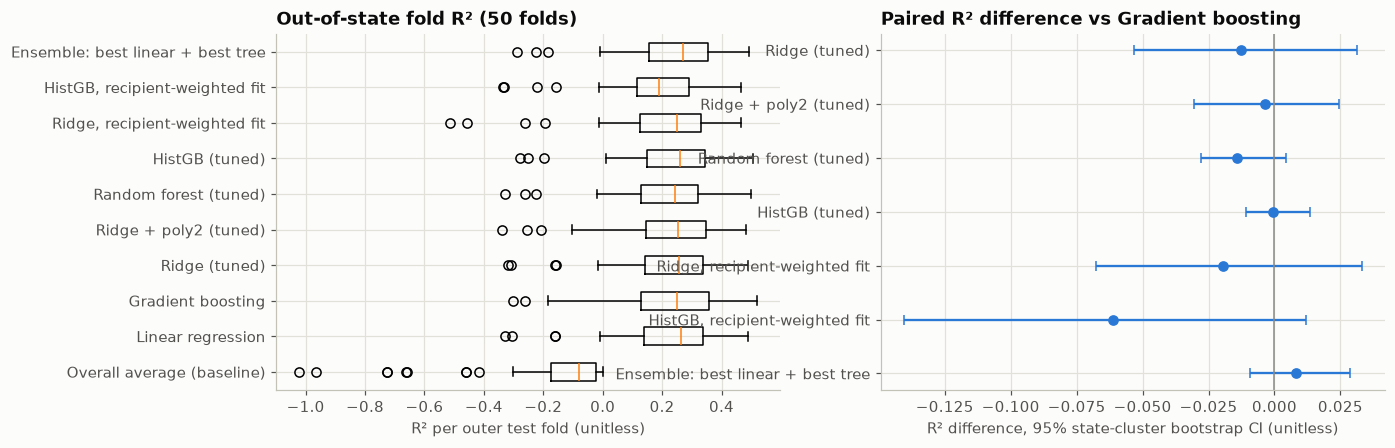

In [91]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.2))
a1.boxplot([FS[n] for n in NAMES], vert=False, tick_labels=NAMES)
a1.set(title="Out-of-state fold R² (50 folds)", xlabel="R² per outer test fold (unitless)")
ypos = np.arange(len(NEW))[::-1]
a2.errorbar(comp.r2_diff, ypos, xerr=[comp.r2_diff - comp.boot_low, comp.boot_high - comp.r2_diff], fmt="o", color=BLUE, capsize=3)
a2.axvline(0, color=GREY, linewidth=1)
a2.set_yticks(ypos, NEW)
a2.set(title=f"Paired R² difference vs {REF_U}", xlabel="R² difference, 95% state-cluster bootstrap CI (unitless)")
fig.savefig(RESULTS / "fig_09_candidates_boxplot_and_paired_diff.png", dpi=150, bbox_inches="tight")
plt.show()

In [92]:
loso_pred = oof_predict(MODELS[REF_U], [np.flatnonzero(state_all == s) for s in states])
aoa = []
for s in states:
    test = np.flatnonzero(state_all == s)
    train = np.setdiff1d(np.arange(len(y_all)), test)
    scaler = StandardScaler().fit(X_all[train])
    dist, _ = NearestNeighbors(n_neighbors=1).fit(scaler.transform(X_all[train])).kneighbors(scaler.transform(X_all[test]))
    aoa.append({"state": s, "counties": len(test), "mean_nn_distance": dist.mean(),
                "rmse": np.sqrt(np.mean((loso_pred[test] - y_all[test]) ** 2))})
aoa = pd.DataFrame(aoa).set_index("state")
rho, rho_p = stats.spearmanr(aoa.mean_nn_distance, aoa.rmse)
aoa.round(3).to_csv(RESULTS / "table_26_area_of_applicability.csv")
print(f"Spearman rho = {rho:.3f}, p = {rho_p:.3g}, across {len(aoa)} states, model = {REF_U}")

Spearman rho = 0.035, p = 0.807, across 51 states, model = Gradient boosting


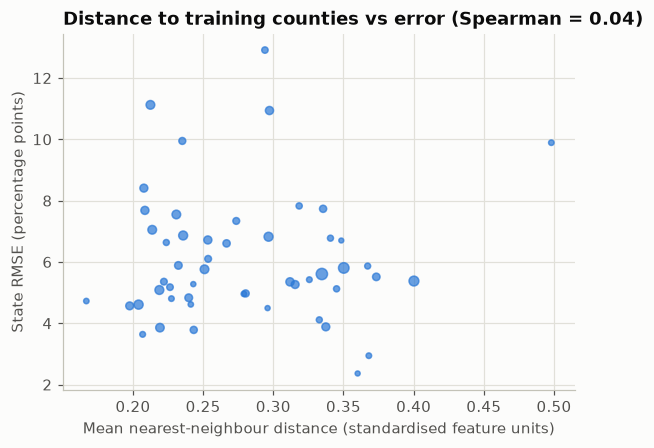

In [93]:
fig, ax = plt.subplots(figsize=(6, 4.2))
ax.scatter(aoa.mean_nn_distance, aoa.rmse, s=aoa.counties.clip(upper=200) / 4 + 10, color=BLUE, alpha=0.7)
ax.set(title=f"Distance to training counties vs error (Spearman = {rho:.2f})",
       xlabel="Mean nearest-neighbour distance (standardised feature units)",
       ylabel="State RMSE (percentage points)")
fig.savefig(RESULTS / "fig_10_aoa_distance_vs_rmse.png", dpi=150, bbox_inches="tight")
plt.show()

In [94]:
print("statsmodels importable:", importlib.util.find_spec("statsmodels") is not None)

statsmodels importable: True


In [95]:
import matplotlib
import scipy
import sklearn

print("numpy", np.__version__, "| pandas", pd.__version__, "| scipy", scipy.__version__,
      "| scikit-learn", sklearn.__version__, "| matplotlib", matplotlib.__version__)

numpy 2.4.6 | pandas 3.1.1 | scipy 1.17.1 | scikit-learn 1.9.1 | matplotlib 3.11.2


In [96]:
"""
PRE-SPECIFIED PLAN (written before the comparison was built)
Question: how does this project's random-vs-grouped validation gap compare with the closest verified published study, and how do its methods compare with the cited guidance?
No published benchmark exists for this outcome (county share of VA recipients rated 70%+), so absolute R2 is NOT compared across studies.
Compared quantity: R2 under random CV minus R2 under group/spatial CV, for the same model type.
Ours: results/table_07_cv_summary.csv (5-fold x 10 repeats). Published: Ploton et al. (2020), R2 0.53 random 10-fold vs 0.14 spatial CV, read on the opened page (research/references.md, source 6).
Different domain, data and predictors, so this is an illustration of the same effect, not a performance contest.
"""

"\nPRE-SPECIFIED PLAN (written before the comparison was built)\nQuestion: how does this project's random-vs-grouped validation gap compare with the closest verified published study, and how do its methods compare with the cited guidance?\nNo published benchmark exists for this outcome (county share of VA recipients rated 70%+), so absolute R2 is NOT compared across studies.\nCompared quantity: R2 under random CV minus R2 under group/spatial CV, for the same model type.\nOurs: results/table_07_cv_summary.csv (5-fold x 10 repeats). Published: Ploton et al. (2020), R2 0.53 random 10-fold vs 0.14 spatial CV, read on the opened page (research/references.md, source 6).\nDifferent domain, data and predictors, so this is an illustration of the same effect, not a performance contest.\n"

In [97]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

RESULTS = Path("../results")
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#8a8a85"
cv = pd.read_csv(RESULTS / "table_07_cv_summary.csv")
cv

,model,scheme,r2,r2_min,r2_max,mae
0,Overall average (baseline),Random folds,-0.001,-0.003,-0.000,6.373
1,Overall average (baseline),State-grouped folds,-0.047,-0.097,-0.012,6.531
2,State average,Random folds,0.618,0.616,0.620,3.848
3,State average,State-grouped folds,-0.047,-0.097,-0.012,6.531
4,Linear regression,Random folds,0.377,0.375,0.379,5.111
5,Linear regression,State-grouped folds,0.329,0.294,0.357,5.304
6,Gradient boosting,Random folds,0.405,0.402,0.409,4.998
7,Gradient boosting,State-grouped folds,0.339,0.308,0.363,5.249


In [98]:
ours = cv.pivot(index="model", columns="scheme", values="r2").rename(
    columns={"Random folds": "r2_random", "State-grouped folds": "r2_grouped"})
published = pd.DataFrame({"r2_random": [0.53], "r2_grouped": [0.14]}, index=["Ploton 2020: random forest, forest biomass"])
gap = pd.concat([ours, published])
gap["drop"] = gap.r2_random - gap.r2_grouped
gap["source"] = ["this project"] * len(ours) + ["Ploton et al. 2020, Nat. Commun. 11:4540"]
gap.round(3).to_csv(RESULTS / "table_27_validation_gap_comparison.csv")
gap.round(3)

,r2_random,r2_grouped,drop,source
Gradient boosting,0.405,0.339,0.066,this project
Linear regression,0.377,0.329,0.048,this project
Overall average (baseline),-0.001,-0.047,0.046,this project
State average,0.618,-0.047,0.665,this project
"Ploton 2020: random forest, forest biomass",0.530,0.140,0.390,"Ploton et al. 2020, Nat. Commun. 11:4540"


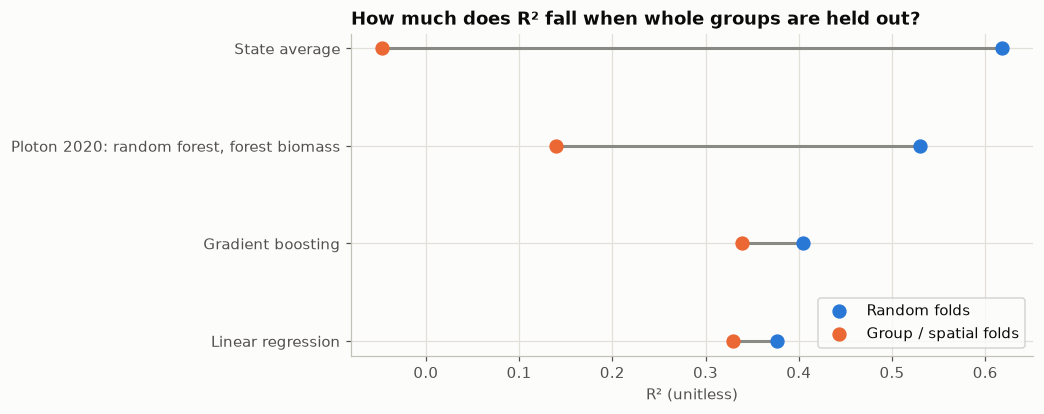

In [99]:
plot = gap.drop(index=["Overall average (baseline)"]).sort_values("r2_random")
fig, ax = plt.subplots(figsize=(8, 3.8))
ypos = range(len(plot))
ax.hlines(ypos, plot.r2_grouped, plot.r2_random, color=GREY, linewidth=2)
ax.scatter(plot.r2_random, ypos, color=BLUE, s=70, label="Random folds", zorder=3)
ax.scatter(plot.r2_grouped, ypos, color=ORANGE, s=70, label="Group / spatial folds", zorder=3)
ax.set_yticks(list(ypos), plot.index)
ax.set(title="How much does R² fall when whole groups are held out?", xlabel="R² (unitless)")
ax.legend(loc="lower right")
fig.savefig(RESULTS / "fig_11_validation_gap_vs_published.png", dpi=150, bbox_inches="tight")
plt.show()

In [100]:
methods = pd.DataFrame(
    [("Random CV is optimistic with dependent data", "Roberts et al. 2017 (source 5)", "Reported random and state-grouped folds side by side"),
     ("Spatial validation can reveal poor performance", "Ploton et al. 2020 (source 6)", "Gap measured: see table above"),
     ("CV error holds only where new data resemble training data", "Meyer and Pebesma 2021 (source 7)", "Nearest-neighbour distance vs state error (notebook 03)"),
     ("Spatial CV may be unjustified; use probability-sample validation", "Wadoux et al. 2021 (source 10)", "Not done: no probability sample available"),
     ("Shrink noisy small-area proportions", "Efron and Morris 1975; Fay and Herriot 1979 (sources 11, 12)", "Not done: listed as a gap in research/research_gaps.md"),
     ("Area-level correlation is not individual-level", "Robinson 1950; Subramanian et al. 2009 (sources 15, 16)", "Stated as a limitation; within-state coefficients reported")],
    columns=["Published point", "Source", "What this project did"])
methods.to_csv(RESULTS / "table_28_method_comparison.csv", index=False)
methods

,Published point,Source,What this project did
0,Random CV is optimistic with dependent data,Roberts et al. 2017 (source 5),Reported random and state-grouped folds side b...
1,Spatial validation can reveal poor performance,Ploton et al. 2020 (source 6),Gap measured: see table above
2,CV error holds only where new data resemble tr...,Meyer and Pebesma 2021 (source 7),Nearest-neighbour distance vs state error (not...
3,Spatial CV may be unjustified; use probability...,Wadoux et al. 2021 (source 10),Not done: no probability sample available
4,Shrink noisy small-area proportions,Efron and Morris 1975; Fay and Herriot 1979 (s...,Not done: listed as a gap in research/research...
5,Area-level correlation is not individual-level,Robinson 1950; Subramanian et al. 2009 (source...,Stated as a limitation; within-state coefficie...
